# Lab 8 — Decision Trees and Support Vector Machines


## 1. Imports and setup

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the Banknote Authentication dataset

In [2]:
# UCI dataset: variance, skewness, curtosis, entropy, class
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
DATA_PATH = Path("data_banknote_authentication.txt")

if not DATA_PATH.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
        print("Dataset downloaded.")
    except Exception as exc:
        raise RuntimeError(
            "Could not download the dataset. Download data_banknote_authentication.txt "
            "from the UCI Banknote Authentication dataset and place it beside this notebook."
        ) from exc

columns = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(DATA_PATH, header=None, names=columns)
print("Dataset shape:", df.shape)
display(df.head())
print("\nClass counts:")
print(df["class"].value_counts())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Class counts:
class
0    762
1    610
Name: count, dtype: int64


## 3. Prepare the data

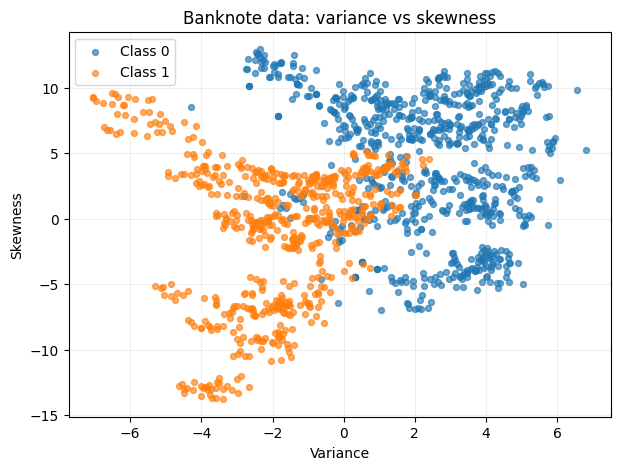

In [3]:
FEATURES_2D = ["variance", "skewness"]

X2 = df[FEATURES_2D].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

plt.figure(figsize=(7, 5))
for label in np.unique(y):
    mask = y == label
    plt.scatter(X2[mask, 0], X2[mask, 1], s=18, alpha=0.65, label=f"Class {label}")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote data: variance vs skewness")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 4. Decision Tree from scratch

This implementation evaluates candidate thresholds using either Gini impurity or entropy. It recursively chooses the split with the greatest impurity reduction and supports maximum depth and minimum leaf-size stopping rules.

In [4]:
class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=4, min_samples_leaf=2):
        if criterion not in {"gini", "entropy"}:
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.n_features_ = None

    def _impurity(self, y):
        if len(y) == 0:
            return 0.0
        _, counts = np.unique(y, return_counts=True)
        probs = counts / counts.sum()
        if self.criterion == "gini":
            return 1.0 - np.sum(probs ** 2)
        probs = probs[probs > 0]
        return -np.sum(probs * np.log2(probs))

    def _best_split(self, X, y):
        parent_impurity = self._impurity(y)
        best_gain, best_feature, best_threshold = 0.0, None, None
        n_samples, n_features = X.shape

        for feature in range(n_features):
            values = np.unique(X[:, feature])
            if len(values) < 2:
                continue
            thresholds = (values[:-1] + values[1:]) / 2.0
            for threshold in thresholds:
                left = X[:, feature] <= threshold
                right = ~left
                if left.sum() < self.min_samples_leaf or right.sum() < self.min_samples_leaf:
                    continue
                weighted = (
                    left.sum() / n_samples * self._impurity(y[left])
                    + right.sum() / n_samples * self._impurity(y[right])
                )
                gain = parent_impurity - weighted
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, feature, threshold

        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):
        values, counts = np.unique(y, return_counts=True)
        node = {"prediction": values[np.argmax(counts)], "samples": len(y)}
        if (len(values) == 1 or depth >= self.max_depth or
                len(y) < 2 * self.min_samples_leaf):
            return node

        feature, threshold, gain = self._best_split(X, y)
        if feature is None or gain <= 1e-12:
            return node

        left = X[:, feature] <= threshold
        node.update({
            "feature": feature, "threshold": float(threshold), "gain": float(gain),
            "left": self._build(X[left], y[left], depth + 1),
            "right": self._build(X[~left], y[~left], depth + 1)
        })
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.n_features_ = X.shape[1]
        self.root = self._build(X, y, 0)
        return self

    def _predict_one(self, row, node):
        while "feature" in node:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        return node["prediction"]

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row, self.root) for row in X])

    def print_rules(self, feature_names=None):
        feature_names = feature_names or [f"x{i}" for i in range(self.n_features_)]
        def walk(node, indent=""):
            if "feature" not in node:
                print(indent + f"Predict class {node['prediction']} (samples={node['samples']})")
                return
            name = feature_names[node["feature"]]
            print(indent + f"if {name} <= {node['threshold']:.4f} (gain={node['gain']:.4f}):")
            walk(node["left"], indent + "  ")
            print(indent + "else:")
            walk(node["right"], indent + "  ")
        walk(self.root)

### Fit the manual tree and inspect its split rules

In [5]:
manual_tree = ManualDecisionTree(criterion="gini", max_depth=4, min_samples_leaf=3)
manual_tree.fit(X2_train, y_train)
manual_tree.print_rules(FEATURES_2D)

if variance <= 0.7651 (gain=0.2435):
  if skewness <= 5.1608 (gain=0.1596):
    if variance <= 0.3202 (gain=0.0222):
      if variance <= -0.4586 (gain=0.0048):
        Predict class 1 (samples=328)
      else:
        Predict class 1 (samples=62)
    else:
      if skewness <= 0.9819 (gain=0.1152):
        Predict class 0 (samples=27)
      else:
        Predict class 1 (samples=19)
  else:
    if variance <= -3.4311 (gain=0.3180):
      if variance <= -4.6585 (gain=0.0219):
        Predict class 1 (samples=24)
      else:
        Predict class 1 (samples=3)
    else:
      if skewness <= 5.5333 (gain=0.0070):
        Predict class 0 (samples=3)
      else:
        Predict class 0 (samples=89)
else:
  if variance <= 1.7907 (gain=0.0211):
    if skewness <= 4.8979 (gain=0.0770):
      if skewness <= 0.1376 (gain=0.1542):
        Predict class 0 (samples=22)
      else:
        Predict class 1 (samples=47)
    else:
      Predict class 0 (samples=41)
  else:
    if variance <= 2.3921 (g

### Visualize manual tree structure

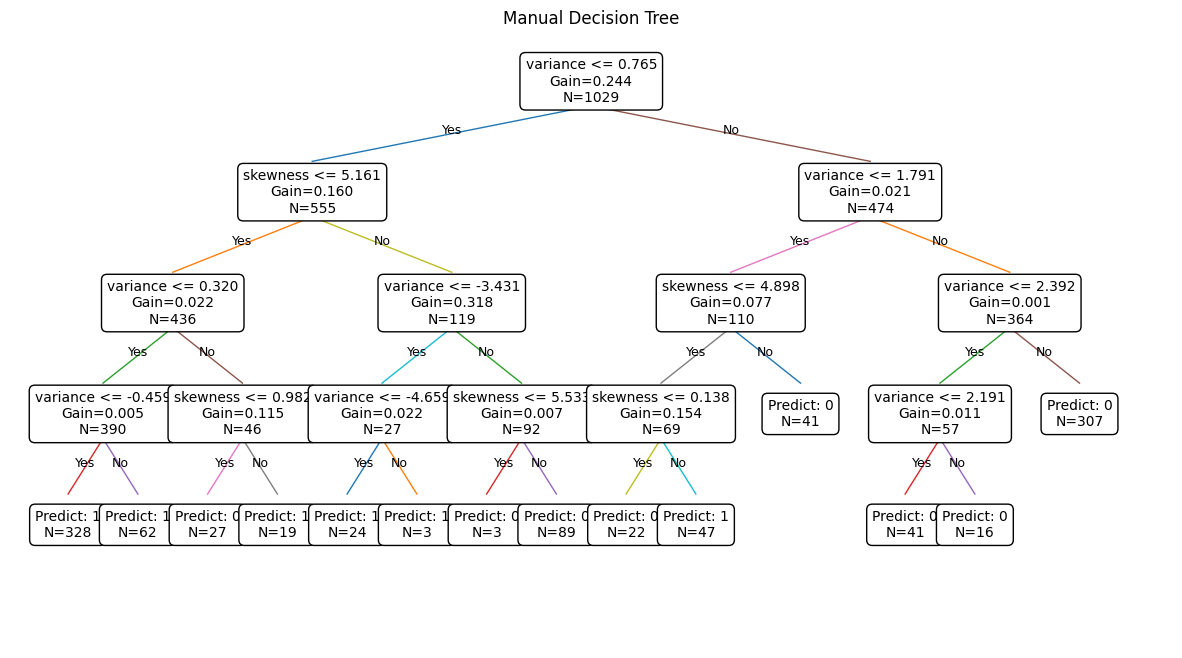

In [6]:
def draw_manual_tree(root, feature_names):
    fig, ax = plt.subplots(figsize=(15, 8))
    ax.axis("off")
    def draw(node, x, y, dx, depth=0):
        if "feature" in node:
            label = f"{feature_names[node['feature']]} <= {node['threshold']:.3f}\nGain={node['gain']:.3f}\nN={node['samples']}"
        else:
            label = f"Predict: {node['prediction']}\nN={node['samples']}"
        ax.text(x, y, label, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="black"))
        if "feature" in node:
            for child, x_child, sign in [(node["left"], x-dx, "Yes"), (node["right"], x+dx, "No")]:
                ax.plot([x, x_child], [y-0.04, y-0.13], linewidth=1)
                ax.text((x+x_child)/2, y-0.085, sign, ha="center", fontsize=9)
                draw(child, x_child, y-0.18, dx/2, depth+1)
    draw(root, 0.5, 0.92, 0.24)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    plt.title("Manual Decision Tree")
    plt.show()

draw_manual_tree(manual_tree.root, FEATURES_2D)

## 5. Decision Tree comparison and 2D decision boundaries

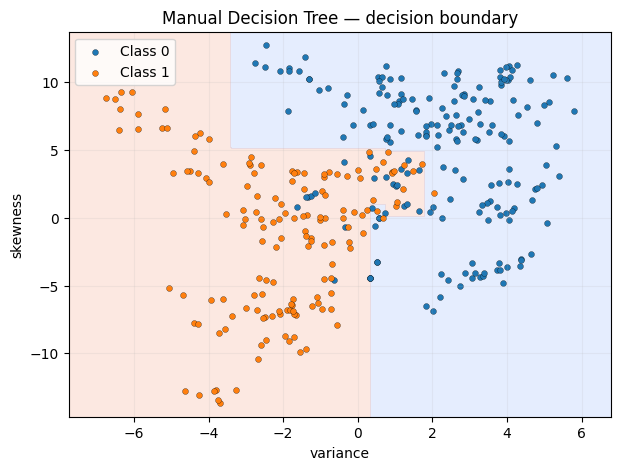

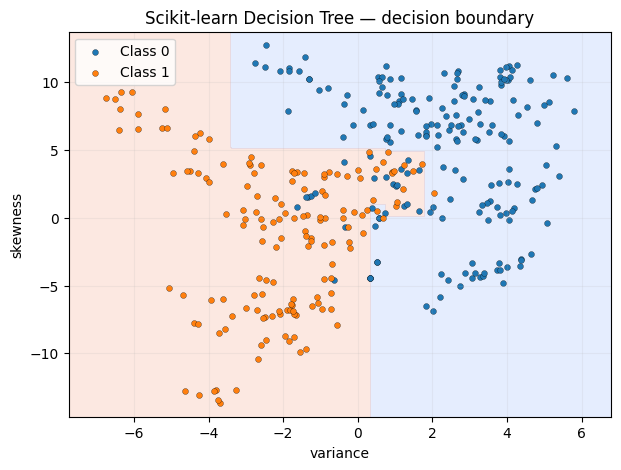

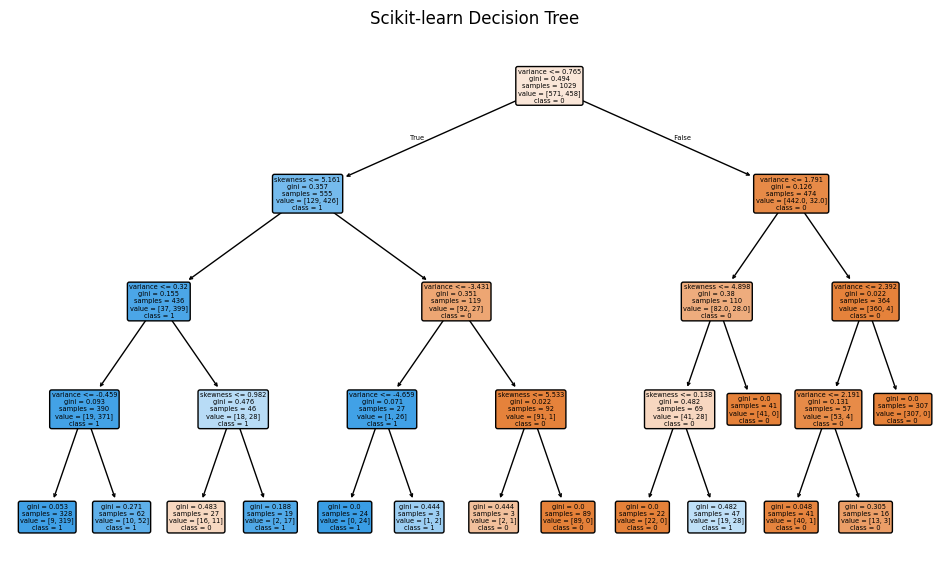

Manual tree accuracy: 0.9300291545189504
Scikit-learn tree accuracy: 0.9300291545189504


In [7]:
sk_tree = DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=3,
                                 random_state=RANDOM_STATE)
sk_tree.fit(X2_train, y_train)

def plot_boundary(model, X, y, title, feature_names=FEATURES_2D, show_margin=False):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(grid)
        zz = (scores >= 0).astype(int).reshape(xx.shape)
    else:
        zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.22, levels=np.arange(-0.5, 2.5, 1), cmap="coolwarm")
    for label in np.unique(y):
        mask = y == label
        plt.scatter(X[mask, 0], X[mask, 1], s=18, label=f"Class {label}", edgecolor="k", linewidth=0.2)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.15)
    plt.show()

plot_boundary(manual_tree, X2_test, y_test, "Manual Decision Tree — decision boundary")
plot_boundary(sk_tree, X2_test, y_test, "Scikit-learn Decision Tree — decision boundary")

plt.figure(figsize=(12, 7))
plot_tree(sk_tree, feature_names=FEATURES_2D, class_names=[str(c) for c in sk_tree.classes_],
          filled=True, rounded=True)
plt.title("Scikit-learn Decision Tree")
plt.show()

print("Manual tree accuracy:", accuracy_score(y_test, manual_tree.predict(X2_test)))
print("Scikit-learn tree accuracy:", accuracy_score(y_test, sk_tree.predict(X2_test)))

### Explore criterion and maximum depth

In [8]:
depth_results = []
for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 4, 5, 6]:
        model = ManualDecisionTree(criterion=criterion, max_depth=depth, min_samples_leaf=3)
        model.fit(X2_train, y_train)
        pred = model.predict(X2_test)
        depth_results.append({
            "criterion": criterion, "max_depth": depth,
            "accuracy": accuracy_score(y_test, pred)
        })
depth_df = pd.DataFrame(depth_results)
display(depth_df)

,criterion,max_depth,accuracy
0,gini,2,0.865889
1,gini,3,0.906706
2,gini,4,0.930029
3,gini,5,0.935860
4,gini,6,0.930029
5,entropy,2,0.865889
6,entropy,3,0.897959
7,entropy,4,0.897959
8,entropy,5,0.924198
9,entropy,6,0.918367


## 6. Linear SVM from scratch

This is a linear soft-margin SVM trained with subgradient descent on the objective

\[
\frac{1}{2}\|w\|^2 + C\sum_i \max(0, 1-y_i(w^Tx_i+b)).
\]

Features are standardized using training-set statistics only. The binary labels are mapped to -1 and +1.

In [9]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, iterations=3000):
        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        y_signed = np.where(y == np.unique(y)[0], -1.0, 1.0)
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        for step in range(self.iterations):
            margins = y_signed * (X @ self.w + self.b)
            active = margins < 1.0
            grad_w = self.w.copy()
            if np.any(active):
                grad_w -= self.C * np.sum((y_signed[active, None] * X[active]), axis=0)
                grad_b = -self.C * np.sum(y_signed[active])
            else:
                grad_b = 0.0
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            if step % 100 == 0 or step == self.iterations - 1:
                margins_now = y_signed * (X @ self.w + self.b)
                hinge = np.maximum(0, 1 - margins_now).sum()
                self.loss_history.append((step, 0.5 * np.dot(self.w, self.w) + self.C * hinge))
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        # The first sorted class is mapped to -1 and the second to +1.
        return np.where(self.decision_function(X) >= 0, self.classes_[1], self.classes_[0])

    def fit_with_classes(self, X, y):
        self.classes_ = np.unique(y)
        return self.fit(X, y)

### Scale features, train manual SVM, and compare with scikit-learn

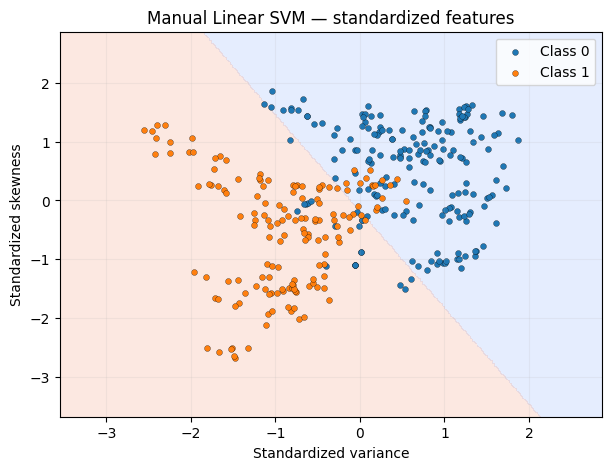

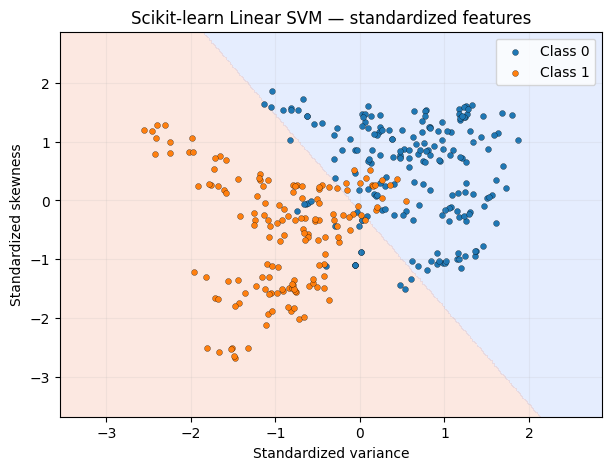

Manual SVM accuracy: 0.8892128279883382
Scikit-learn linear SVM accuracy: 0.8892128279883382


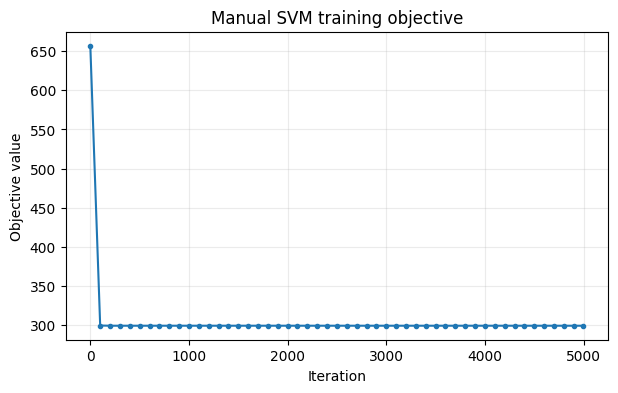

In [10]:
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

manual_svm = ManualLinearSVM(C=1.0, learning_rate=0.0005, iterations=5000)
manual_svm.fit_with_classes(X2_train_scaled, y_train)

sk_svm = SVC(kernel="linear", C=1.0)
sk_svm.fit(X2_train_scaled, y_train)

plot_boundary(manual_svm, X2_test_scaled, y_test, "Manual Linear SVM — standardized features",
              feature_names=["Standardized variance", "Standardized skewness"])
plot_boundary(sk_svm, X2_test_scaled, y_test, "Scikit-learn Linear SVM — standardized features",
              feature_names=["Standardized variance", "Standardized skewness"])

print("Manual SVM accuracy:", accuracy_score(y_test, manual_svm.predict(X2_test_scaled)))
print("Scikit-learn linear SVM accuracy:", accuracy_score(y_test, sk_svm.predict(X2_test_scaled)))

plt.figure(figsize=(7, 4))
loss_steps, losses = zip(*manual_svm.loss_history)
plt.plot(loss_steps, losses, marker=".")
plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("Manual SVM training objective")
plt.grid(alpha=0.25)
plt.show()

### Plot separating line, margins, and margin-violating samples

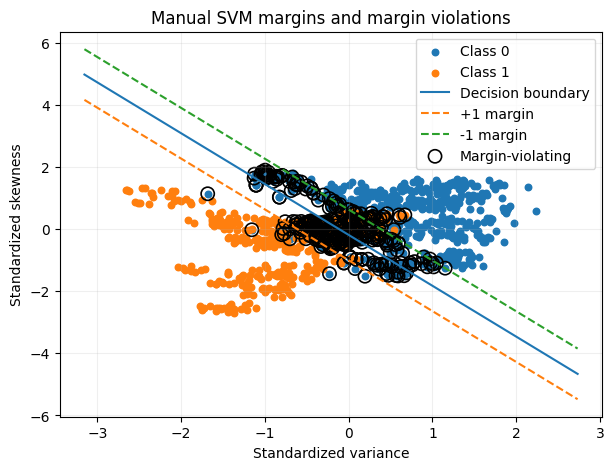

In [11]:
def plot_svm_margins(model, X, y, title):
    plt.figure(figsize=(7, 5))
    for label in np.unique(y):
        mask = y == label
        plt.scatter(X[mask, 0], X[mask, 1], s=22, label=f"Class {label}")
    w = model.w
    b = model.b
    x_vals = np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 300)
    if abs(w[1]) > 1e-10:
        plt.plot(x_vals, -(w[0] * x_vals + b) / w[1], label="Decision boundary")
        plt.plot(x_vals, -(w[0] * x_vals + b - 1) / w[1], "--", label="+1 margin")
        plt.plot(x_vals, -(w[0] * x_vals + b + 1) / w[1], "--", label="-1 margin")
    signed = np.where(y == np.unique(y)[0], -1, 1)
    violating = signed * model.decision_function(X) < 1
    plt.scatter(X[violating, 0], X[violating, 1], s=90, facecolors="none",
                edgecolors="black", linewidths=1.2, label="Margin-violating")
    plt.xlabel("Standardized variance")
    plt.ylabel("Standardized skewness")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

plot_svm_margins(manual_svm, X2_train_scaled, y_train, "Manual SVM margins and margin violations")

### Study regularization, learning rate, and iterations

In [12]:
svm_tuning = []
for C in [0.1, 1.0, 10.0]:
    for lr, iterations in [(0.0002, 3000), (0.0005, 5000), (0.001, 5000)]:
        model = ManualLinearSVM(C=C, learning_rate=lr, iterations=iterations)
        model.fit_with_classes(X2_train_scaled, y_train)
        svm_tuning.append({
            "C": C, "learning_rate": lr, "iterations": iterations,
            "accuracy": accuracy_score(y_test, model.predict(X2_test_scaled))
        })
display(pd.DataFrame(svm_tuning))

,C,learning_rate,iterations,accuracy
0,0.1,0.0002,3000,0.883382
1,0.1,0.0005,5000,0.883382
2,0.1,0.0010,5000,0.883382
3,1.0,0.0002,3000,0.889213
4,1.0,0.0005,5000,0.889213
5,1.0,0.0010,5000,0.889213
6,10.0,0.0002,3000,0.889213
7,10.0,0.0005,5000,0.889213
8,10.0,0.0010,5000,0.892128


## 7. Nonlinear SVM kernels on a synthetic dataset

linear kernel accuracy: 0.8480


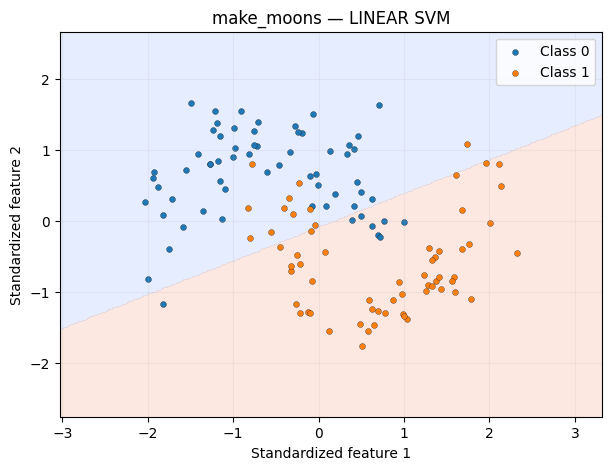

poly kernel accuracy: 0.8400


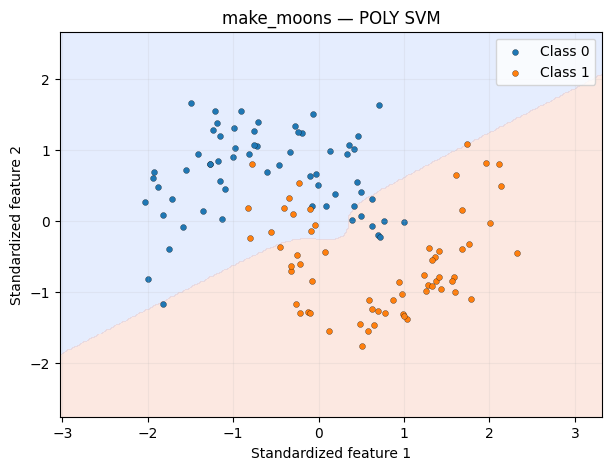

rbf kernel accuracy: 0.9760


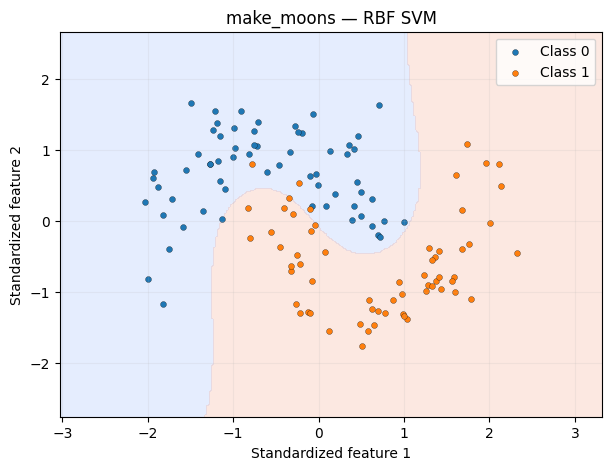

In [13]:
X_moon, y_moon = make_moons(n_samples=500, noise=0.22, random_state=RANDOM_STATE)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_moon, y_moon, test_size=0.25, random_state=RANDOM_STATE, stratify=y_moon
)
moon_scaler = StandardScaler()
Xm_train_s = moon_scaler.fit_transform(Xm_train)
Xm_test_s = moon_scaler.transform(Xm_test)

kernel_models = {}
for kernel in ["linear", "poly", "rbf"]:
    model = SVC(kernel=kernel, C=1.0, degree=3, gamma="scale")
    model.fit(Xm_train_s, ym_train)
    kernel_models[kernel] = model
    print(f"{kernel} kernel accuracy: {accuracy_score(ym_test, model.predict(Xm_test_s)):.4f}")
    plot_boundary(model, Xm_test_s, ym_test, f"make_moons — {kernel.upper()} SVM",
                  feature_names=["Standardized feature 1", "Standardized feature 2"])

**Interpretation prompt:** Compare the shapes of the boundaries. A linear kernel can only form a straight boundary in the input space. Polynomial and RBF kernels can represent curved boundaries, which may fit the moon-shaped structure more naturally. The more flexible boundary can also overfit, depending on the data and hyperparameters.

## 8. Final comparison using all four Banknote features

In [14]:
X4 = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y4 = df["class"].to_numpy(dtype=int)
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.25, random_state=RANDOM_STATE, stratify=y4
)

# Fit the scaler only on training data; SVMs use standardized features.
scaler4 = StandardScaler()
X4_train_s = scaler4.fit_transform(X4_train)
X4_test_s = scaler4.transform(X4_test)

def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - t0
    t1 = time.perf_counter()
    pred = model.predict(X_test)
    predict_seconds = time.perf_counter() - t1
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1_score": f1_score(y_test, pred, zero_division=0),
        "training_time_sec": train_seconds,
        "prediction_time_sec": predict_seconds
    }

final_rows = []

manual_tree4 = ManualDecisionTree(criterion="gini", max_depth=5, min_samples_leaf=3)
final_rows.append(evaluate_model("Manual Decision Tree", manual_tree4,
                                 X4_train, y4_train, X4_test, y4_test))

sk_tree4 = DecisionTreeClassifier(criterion="gini", max_depth=5, min_samples_leaf=3,
                                  random_state=RANDOM_STATE)
final_rows.append(evaluate_model("Scikit-learn Decision Tree", sk_tree4,
                                 X4_train, y4_train, X4_test, y4_test))

manual_svm4 = ManualLinearSVM(C=1.0, learning_rate=0.0002, iterations=6000)
manual_svm4.fit_with_classes(X4_train_s, y4_train)
# Time prediction separately; training was performed above to preserve the class mapping.
t0 = time.perf_counter()
manual_svm4.fit_with_classes(X4_train_s, y4_train)
manual_train_time = time.perf_counter() - t0
t1 = time.perf_counter()
manual_pred4 = manual_svm4.predict(X4_test_s)
manual_predict_time = time.perf_counter() - t1
final_rows.append({
    "model": "Manual Linear SVM",
    "accuracy": accuracy_score(y4_test, manual_pred4),
    "precision": precision_score(y4_test, manual_pred4, zero_division=0),
    "recall": recall_score(y4_test, manual_pred4, zero_division=0),
    "f1_score": f1_score(y4_test, manual_pred4, zero_division=0),
    "training_time_sec": manual_train_time,
    "prediction_time_sec": manual_predict_time
})

sk_linear4 = SVC(kernel="linear", C=1.0)
final_rows.append(evaluate_model("Scikit-learn Linear SVM", sk_linear4,
                                 X4_train_s, y4_train, X4_test_s, y4_test))

sk_rbf4 = SVC(kernel="rbf", C=1.0, gamma="scale")
final_rows.append(evaluate_model("Scikit-learn RBF SVM", sk_rbf4,
                                 X4_train_s, y4_train, X4_test_s, y4_test))

results = pd.DataFrame(final_rows)
display(results.round(4))

,model,accuracy,precision,recall,f1_score,training_time_sec,prediction_time_sec
0,Manual Decision Tree,0.9825,0.9679,0.9934,0.9805,1.6031,0.0004
1,Scikit-learn Decision Tree,0.9825,0.9679,0.9934,0.9805,0.0047,0.0005
2,Manual Linear SVM,0.9767,0.9500,1.0000,0.9744,0.4235,0.0001
3,Scikit-learn Linear SVM,0.9767,0.9500,1.0000,0.9744,0.0100,0.0011
4,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0048,0.0036


## 9. Final comparison visualization

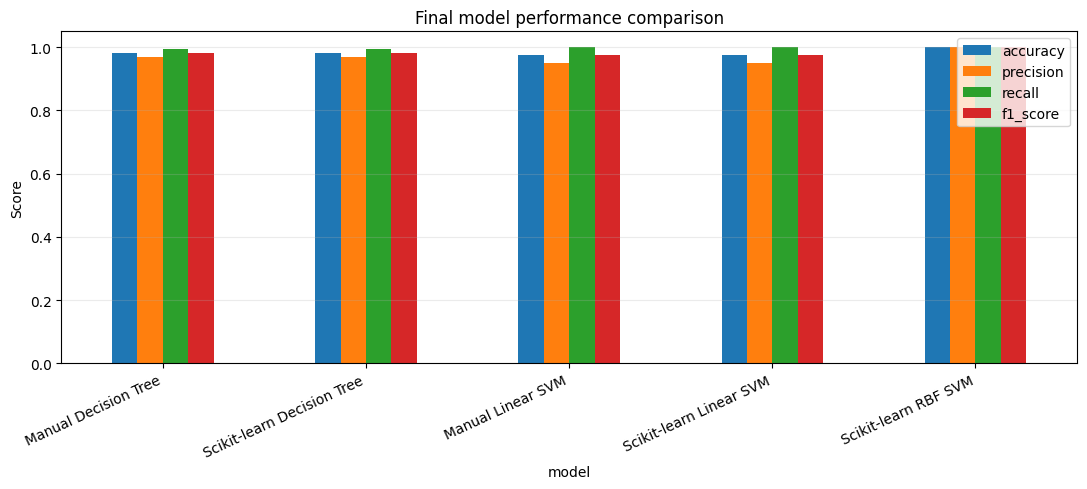

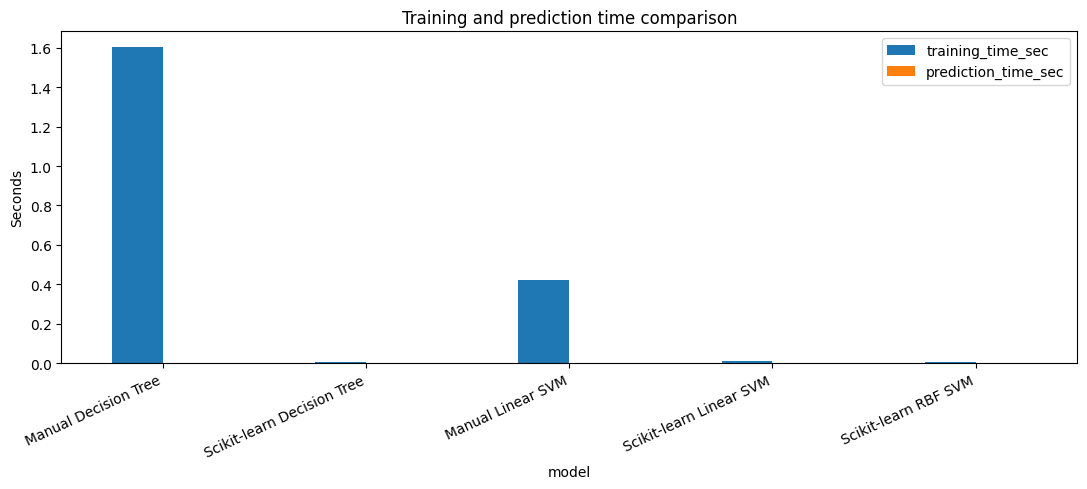

In [15]:
metric_cols = ["accuracy", "precision", "recall", "f1_score"]
results.set_index("model")[metric_cols].plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
plt.ylabel("Score")
plt.title("Final model performance comparison")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

results.set_index("model")[["training_time_sec", "prediction_time_sec"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.ylabel("Seconds")
plt.title("Training and prediction time comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 10. Discussion and conclusion


1. **Accuracy and F1-score:** Which model performs best on the held-out test set? Are precision and recall balanced?
2. **Interpretability:** The Decision Tree can be explained through feature-threshold rules. SVM decisions depend on a learned separating boundary.
3. **Feature scaling:** SVMs are sensitive to feature scales, so scaling based only on training data is important. Trees generally do not require scaling.
4. **Overfitting and complexity:** Deeper trees can fit training data more closely but may generalize worse. Kernel SVMs can capture nonlinear patterns, but flexibility and regularization affect generalization.
5. **Implementation limitations:** The manual tree searches candidate thresholds and can be slower than optimized libraries. The manual SVM uses a basic subgradient update and may need tuning of learning rate, iterations, and C.
6. **Reproducibility:** The train-test split uses a fixed random seed. Timings vary by machine and current system load.


### Conclusion
- Implemented Decision Tree and Linear SVM classifiers from scratch.
- Compared manual implementations with scikit-learn models.
- Visualized decision boundaries, tree structures, and SVM margins.
- Explored Gini impurity, entropy, and hyperparameter tuning.
- Compared linear, polynomial, and RBF SVM kernels.
- Evaluated models using accuracy, precision, recall, F1-score, and execution time.
- Observed the importance of feature scaling, interpretability, and model complexity.
- Gained practical understanding of classification algorithms and model evaluation.